In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Sales Project Started!")


Sales Project Started!


In [2]:

df = pd.read_csv("sales_data_beginner.csv")

print(df.head())


   Order_ID        Date   Product     Category    City  Quantity  Unit_Price  \
0      1001  2026-01-05    Laptop  Electronics   Delhi         2       55000   
1      1002  2026-01-08     Mouse  Accessories  Mumbai         5         500   
2      1003  2026-01-15  Keyboard  Accessories   Delhi         3        1200   
3      1004  2026-01-21    Laptop  Electronics  Jaipur         1       55000   
4      1005  2026-02-02   Monitor  Electronics  Mumbai         2       12000   

   Revenue  
0   110000  
1     2500  
2     3600  
3    55000  
4    24000  


In [3]:

print("Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Information:")
df.info()


Rows and Columns:
(12, 8)

Column Names:
['Order_ID', 'Date', 'Product', 'Category', 'City', 'Quantity', 'Unit_Price', 'Revenue']

Data Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Order_ID    12 non-null     int64 
 1   Date        12 non-null     object
 2   Product     12 non-null     object
 3   Category    12 non-null     object
 4   City        12 non-null     object
 5   Quantity    12 non-null     int64 
 6   Unit_Price  12 non-null     int64 
 7   Revenue     12 non-null     int64 
dtypes: int64(4), object(4)
memory usage: 900.0+ bytes


In [4]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


Missing values:
Order_ID      0
Date          0
Product       0
Category      0
City          0
Quantity      0
Unit_Price    0
Revenue       0
dtype: int64

Duplicate rows:
0


In [5]:

total_sales = df["Revenue"].sum()

print("Total Sales: ₹", total_sales)


Total Sales: ₹ 344500


In [6]:

average_sales = df["Revenue"].mean()

print("Average Order Revenue: ₹", round(average_sales, 2))


Average Order Revenue: ₹ 28708.33


In [7]:

product_sales = df.groupby("Product")["Revenue"].sum()

print(product_sales.sort_values(ascending=False))


Product
Laptop      275000
Monitor      48000
Keyboard     12000
Mouse         9500
Name: Revenue, dtype: int64


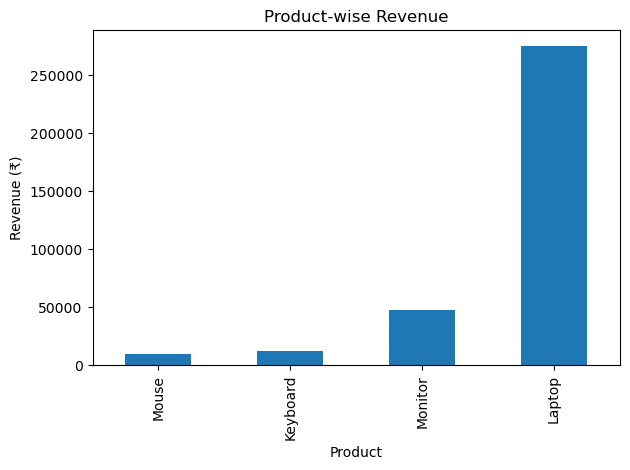

In [8]:

product_sales.sort_values().plot(
    kind="bar",
    title="Product-wise Revenue",
    xlabel="Product",
    ylabel="Revenue (₹)"
)

plt.tight_layout()
plt.show()


In [9]:

city_sales = df.groupby("City")["Revenue"].sum()

print(city_sales.sort_values(ascending=False))


City
Delhi        145200
Mumbai        81500
Jaipur        59800
Bengaluru     58000
Name: Revenue, dtype: int64


In [10]:

df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.month_name()

print(df[["Date", "Month", "Revenue"]].head())


        Date     Month  Revenue
0 2026-01-05   January   110000
1 2026-01-08   January     2500
2 2026-01-15   January     3600
3 2026-01-21   January    55000
4 2026-02-02  February    24000


In [11]:

monthly_sales = df.groupby("Month")["Revenue"].sum()

print(monthly_sales)


Month
February     87800
January     171100
March        85600
Name: Revenue, dtype: int64


In [12]:

df["Month_Number"] = df["Date"].dt.month

monthly_sales = (
    df.groupby("Month_Number")["Revenue"]
    .sum()
    .sort_index()
)

print(monthly_sales)


Month_Number
1    171100
2     87800
3     85600
Name: Revenue, dtype: int64


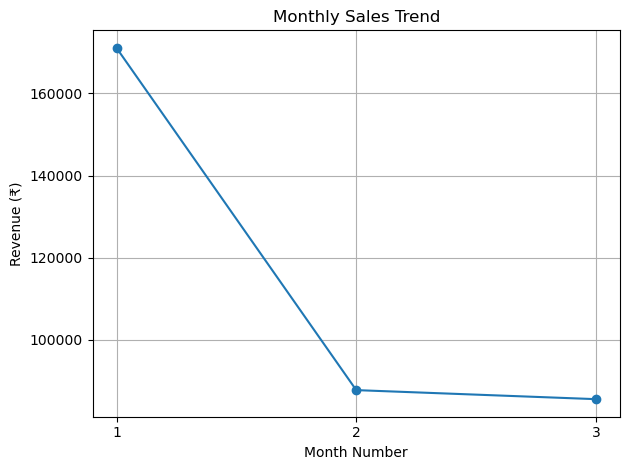

In [13]:

monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend",
    xlabel="Month Number",
    ylabel="Revenue (₹)"
)

plt.xticks([1, 2, 3])
plt.grid(True)
plt.tight_layout()
plt.show()


In [14]:

revenues = df["Revenue"].to_numpy()

print("Total Revenue:", np.sum(revenues))
print("Average Revenue:", round(np.mean(revenues), 2))
print("Maximum Revenue:", np.max(revenues))
print("Minimum Revenue:", np.min(revenues))


Total Revenue: 344500
Average Revenue: 28708.33
Maximum Revenue: 110000
Minimum Revenue: 2500


In [15]:

best_product = product_sales.idxmax()
top_city = city_sales.idxmax()

print("Best Revenue Product:", best_product)
print("Top Revenue City:", top_city)


Best Revenue Product: Laptop
Top Revenue City: Delhi


<Axes: xlabel='Month_Number'>

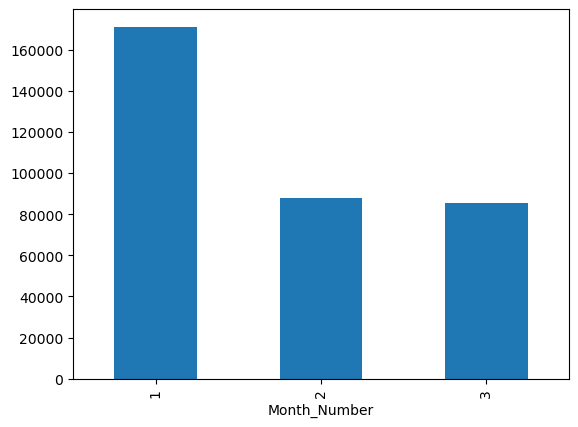

In [16]:
product_sales.idxmin()
df["Quantity"].sum()
monthly_sales.plot(kind="bar")

In [17]:

import sqlite3

conn = sqlite3.connect("sales_database.db")

print("Database connected successfully!")


Database connected successfully!


In [18]:

df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Sales data saved in database!")


Sales data saved in database!


In [19]:

query = "SELECT * FROM sales"

result = pd.read_sql_query(query, conn)

print(result.head())


   Order_ID                 Date   Product     Category    City  Quantity  \
0      1001  2026-01-05 00:00:00    Laptop  Electronics   Delhi         2   
1      1002  2026-01-08 00:00:00     Mouse  Accessories  Mumbai         5   
2      1003  2026-01-15 00:00:00  Keyboard  Accessories   Delhi         3   
3      1004  2026-01-21 00:00:00    Laptop  Electronics  Jaipur         1   
4      1005  2026-02-02 00:00:00   Monitor  Electronics  Mumbai         2   

   Unit_Price  Revenue     Month  Month_Number  
0       55000   110000   January             1  
1         500     2500   January             1  
2        1200     3600   January             1  
3       55000    55000   January             1  
4       12000    24000  February             2  


In [20]:

query = """
SELECT SUM(Revenue) AS Total_Revenue
FROM sales
"""

result = pd.read_sql_query(query, conn)

print(result)


   Total_Revenue
0         344500


In [21]:

query = """
SELECT Product, SUM(Revenue) AS Total_Revenue
FROM sales
GROUP BY Product
ORDER BY Total_Revenue DESC
"""

result = pd.read_sql_query(query, conn)

print(result)


    Product  Total_Revenue
0    Laptop         275000
1   Monitor          48000
2  Keyboard          12000
3     Mouse           9500


In [24]:
"City-wise sales"
query = """
SELECT City, SUM(Revenue) AS Total_Revenue
FROM sales
GROUP BY City
ORDER BY Total_Revenue DESC
"""

city_result = pd.read_sql_query(query, conn)

print(city_result)


        City  Total_Revenue
0      Delhi         145200
1     Mumbai          81500
2     Jaipur          59800
3  Bengaluru          58000


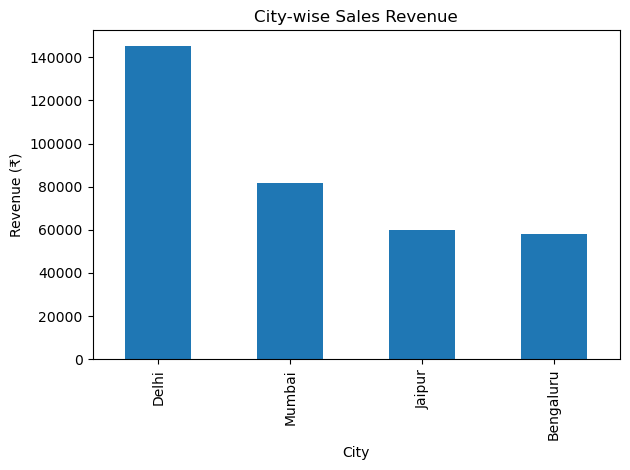

In [25]:
"SQL result ka chart banao"

city_result.plot(
    kind="bar",
    x="City",
    y="Total_Revenue",
    title="City-wise Sales Revenue",
    xlabel="City",
    ylabel="Revenue (₹)",
    legend=False
)

plt.tight_layout()
plt.show()


In [26]:
"Database connection close karo"

conn.close()

print("Database connection closed!")


Database connection closed!


In [27]:
"Key performance indicators (KPIs)"

total_revenue = df["Revenue"].sum()
total_orders = df["Order_ID"].nunique()
total_quantity = df["Quantity"].sum()
average_order_revenue = df["Revenue"].mean()

print("===== SALES REPORT =====")
print("Total Revenue: ₹", total_revenue)
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Average Order Revenue: ₹", round(average_order_revenue, 2))


===== SALES REPORT =====
Total Revenue: ₹ 344500
Total Orders: 12
Total Quantity Sold: 38
Average Order Revenue: ₹ 28708.33


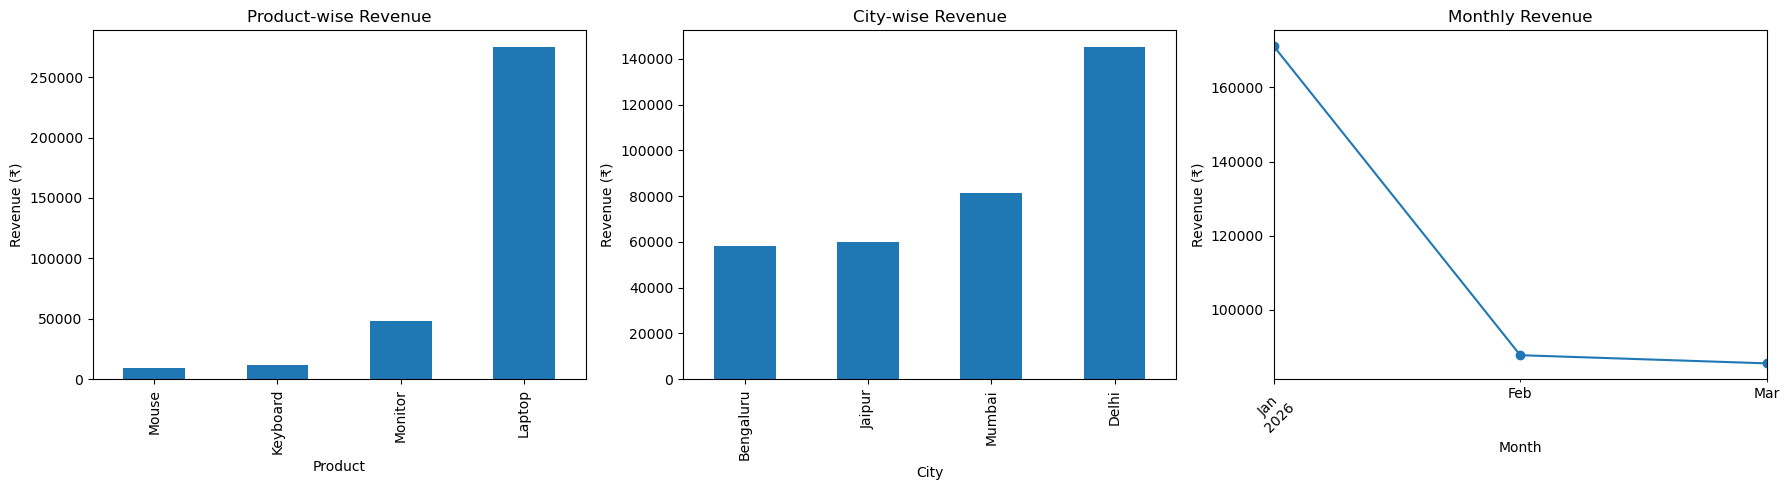

In [28]:
"Ek mini Sales Dashboard banao"

# Product-wise revenue
product_sales = df.groupby("Product")["Revenue"].sum()

# City-wise revenue
city_sales = df.groupby("City")["Revenue"].sum()

# Monthly revenue
df["Date"] = pd.to_datetime(df["Date"])
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Revenue"].sum()

# Dashboard
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

product_sales.sort_values().plot(
    kind="bar", ax=axes[0], title="Product-wise Revenue"
)
axes[0].set_xlabel("Product")
axes[0].set_ylabel("Revenue (₹)")

city_sales.sort_values().plot(
    kind="bar", ax=axes[1], title="City-wise Revenue"
)
axes[1].set_xlabel("City")
axes[1].set_ylabel("Revenue (₹)")

monthly_sales.plot(
    kind="line", marker="o", ax=axes[2], title="Monthly Revenue"
)
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Revenue (₹)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [29]:
"Automatic business insights nikalo"

best_product = product_sales.idxmax()
best_city = city_sales.idxmax()
best_month = monthly_sales.idxmax()

print("===== BUSINESS INSIGHTS =====")
print("Top Product:", best_product)
print("Top City:", best_city)
print("Best Sales Month:", best_month)


===== BUSINESS INSIGHTS =====
Top Product: Laptop
Top City: Delhi
Best Sales Month: 2026-01


In [30]:
"Final report CSV mein save karo"

report = pd.DataFrame({
    "Product": product_sales.index,
    "Total_Revenue": product_sales.values
})

report.to_csv("product_sales_report.csv", index=False)

print("Report saved successfully!")


Report saved successfully!
